In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor

from sklearn.metrics import (
    r2_score,
    mean_squared_error,
    mean_absolute_error
)

In [4]:
data = pd.read_csv("uber.csv")

print(data.head())
print(data.shape)
print(data.info())

   Unnamed: 0                            key  fare_amount  \
0    24238194    2015-05-07 19:52:06.0000003          7.5   
1    27835199    2009-07-17 20:04:56.0000002          7.7   
2    44984355   2009-08-24 21:45:00.00000061         12.9   
3    25894730    2009-06-26 08:22:21.0000001          5.3   
4    17610152  2014-08-28 17:47:00.000000188         16.0   

           pickup_datetime  pickup_longitude  pickup_latitude  \
0  2015-05-07 19:52:06 UTC        -73.999817        40.738354   
1  2009-07-17 20:04:56 UTC        -73.994355        40.728225   
2  2009-08-24 21:45:00 UTC        -74.005043        40.740770   
3  2009-06-26 08:22:21 UTC        -73.976124        40.790844   
4  2014-08-28 17:47:00 UTC        -73.925023        40.744085   

   dropoff_longitude  dropoff_latitude  passenger_count  
0         -73.999512         40.723217              1.0  
1         -73.994710         40.750325              1.0  
2         -73.962565         40.772647              1.0  
3         

In [5]:
# Remove missing values
data = data.dropna()

# Remove duplicate records
data = data.drop_duplicates()

# Remove invalid fare amounts
data = data[data["fare_amount"] > 0]

# Remove invalid passenger counts
data = data[data["passenger_count"] > 0]

print(data.isnull().sum())
print(data.head())

Unnamed: 0           0
key                  0
fare_amount          0
pickup_datetime      0
pickup_longitude     0
pickup_latitude      0
dropoff_longitude    0
dropoff_latitude     0
passenger_count      0
dtype: int64
   Unnamed: 0                            key  fare_amount  \
0    24238194    2015-05-07 19:52:06.0000003          7.5   
1    27835199    2009-07-17 20:04:56.0000002          7.7   
2    44984355   2009-08-24 21:45:00.00000061         12.9   
3    25894730    2009-06-26 08:22:21.0000001          5.3   
4    17610152  2014-08-28 17:47:00.000000188         16.0   

           pickup_datetime  pickup_longitude  pickup_latitude  \
0  2015-05-07 19:52:06 UTC        -73.999817        40.738354   
1  2009-07-17 20:04:56 UTC        -73.994355        40.728225   
2  2009-08-24 21:45:00 UTC        -74.005043        40.740770   
3  2009-06-26 08:22:21 UTC        -73.976124        40.790844   
4  2014-08-28 17:47:00 UTC        -73.925023        40.744085   

   dropoff_longitude  

In [6]:
def haversine(lat1, lon1, lat2, lon2):

    R = 6371

    lat1 = np.radians(lat1)
    lon1 = np.radians(lon1)

    lat2 = np.radians(lat2)
    lon2 = np.radians(lon2)

    dlat = lat2 - lat1
    dlon = lon2 - lon1

    a = np.sin(dlat / 2)**2 + \
        np.cos(lat1) * np.cos(lat2) * np.sin(dlon / 2)**2

    c = 2 * np.arcsin(np.sqrt(a))

    return R * c


data["distance"] = haversine(
    data["pickup_latitude"],
    data["pickup_longitude"],
    data["dropoff_latitude"],
    data["dropoff_longitude"]
)

print(data[["fare_amount", "distance"]].head())

   fare_amount  distance
0          7.5  1.683323
1          7.7  2.457590
2         12.9  5.036377
3          5.3  1.661683
4         16.0  4.475450


In [7]:
X = data[[
    "pickup_longitude",
    "pickup_latitude",
    "dropoff_longitude",
    "dropoff_latitude",
    "passenger_count",
    "distance"
]]

y = data["fare_amount"]

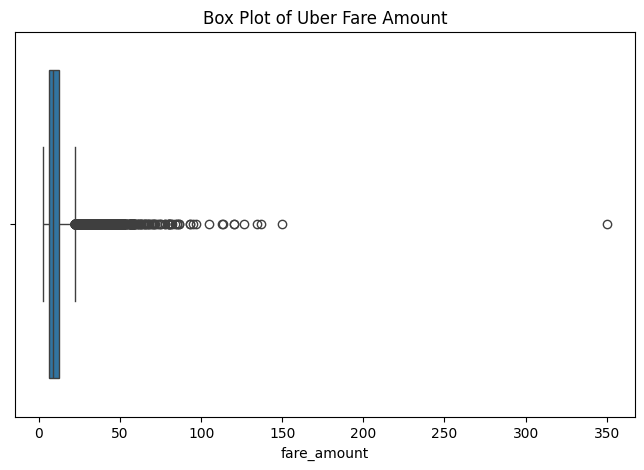

In [8]:
plt.figure(figsize=(8, 5))

sns.boxplot(x=data["fare_amount"])

plt.title("Box Plot of Uber Fare Amount")
plt.show()

In [9]:
Q1 = data["fare_amount"].quantile(0.25)

Q3 = data["fare_amount"].quantile(0.75)

IQR = Q3 - Q1

lower_limit = Q1 - 1.5 * IQR

upper_limit = Q3 + 1.5 * IQR

data = data[
    (data["fare_amount"] >= lower_limit) &
    (data["fare_amount"] <= upper_limit)
]

print("Dataset after removing outliers:")
print(data.shape)

Dataset after removing outliers:
(16260, 10)


In [10]:
X = data[[
    "pickup_longitude",
    "pickup_latitude",
    "dropoff_longitude",
    "dropoff_latitude",
    "passenger_count",
    "distance"
]]

y = data["fare_amount"]

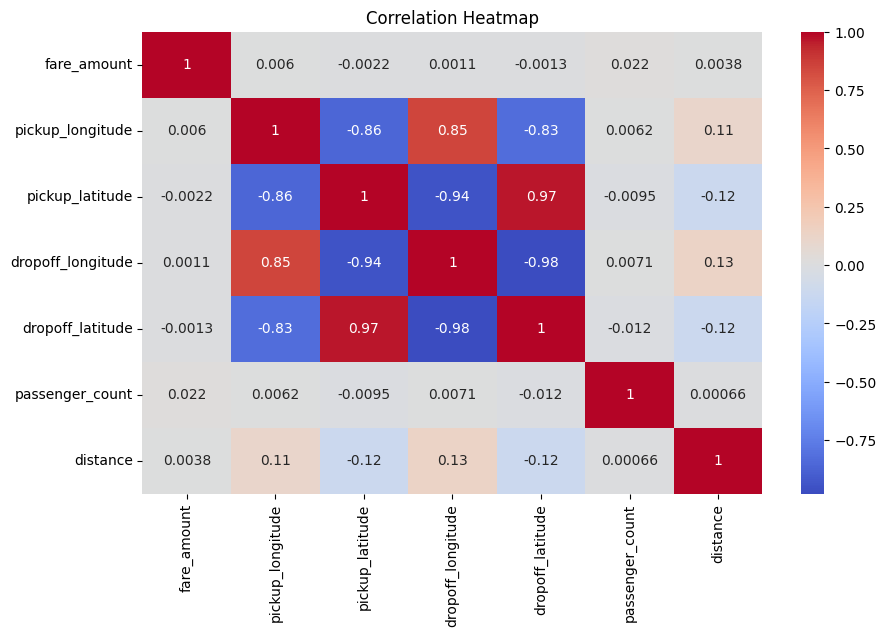

In [11]:
plt.figure(figsize=(10, 6))

sns.heatmap(
    data[[
        "fare_amount",
        "pickup_longitude",
        "pickup_latitude",
        "dropoff_longitude",
        "dropoff_latitude",
        "passenger_count",
        "distance"
    ]].corr(),
    annot=True,
    cmap="coolwarm"
)

plt.title("Correlation Heatmap")
plt.show()

In [12]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Training data:", X_train.shape)

print("Testing data:", X_test.shape)

Training data: (13008, 6)
Testing data: (3252, 6)


In [13]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)

X_test_scaled = scaler.transform(X_test)

In [14]:
lr = LinearRegression()

lr.fit(X_train_scaled, y_train)

y_pred_lr = lr.predict(X_test_scaled)

print("Linear Regression R2 Score:",
      r2_score(y_test, y_pred_lr))

print("Linear Regression RMSE:",
      np.sqrt(mean_squared_error(y_test, y_pred_lr)))

print("Linear Regression MAE:",
      mean_absolute_error(y_test, y_pred_lr))

Linear Regression R2 Score: -0.0006138925077066038
Linear Regression RMSE: 4.165366701550321
Linear Regression MAE: 3.3079055684058667


In [15]:
rf = RandomForestRegressor(
    n_estimators=100,
    random_state=42
)

rf.fit(X_train, y_train)

y_pred_rf = rf.predict(X_test)

print("Random Forest R2 Score:",
      r2_score(y_test, y_pred_rf))

print("Random Forest RMSE:",
      np.sqrt(mean_squared_error(y_test, y_pred_rf)))

print("Random Forest MAE:",
      mean_absolute_error(y_test, y_pred_rf))

Random Forest R2 Score: 0.6771445389475285
Random Forest RMSE: 2.366050692668042
Random Forest MAE: 1.6852115643150207


In [16]:
results = pd.DataFrame({
    "Model": [
        "Linear Regression",
        "Random Forest"
    ],

    "R2 Score": [
        r2_score(y_test, y_pred_lr),
        r2_score(y_test, y_pred_rf)
    ],

    "RMSE": [
        np.sqrt(mean_squared_error(y_test, y_pred_lr)),
        np.sqrt(mean_squared_error(y_test, y_pred_rf))
    ],

    "MAE": [
        mean_absolute_error(y_test, y_pred_lr),
        mean_absolute_error(y_test, y_pred_rf)
    ]
})

print(results)

               Model  R2 Score      RMSE       MAE
0  Linear Regression -0.000614  4.165367  3.307906
1      Random Forest  0.677145  2.366051  1.685212


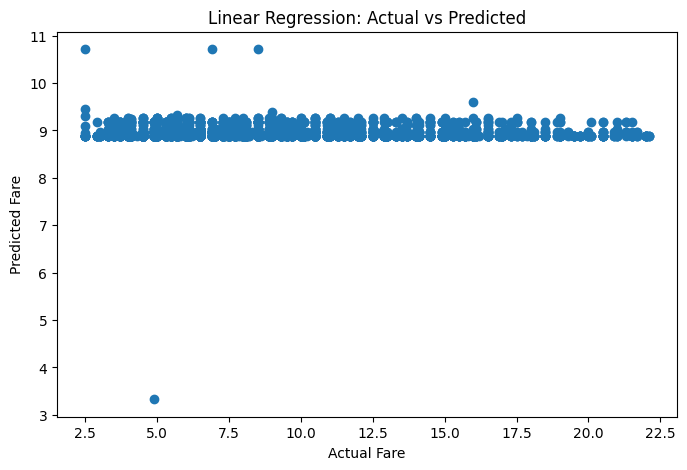

In [17]:
plt.figure(figsize=(8, 5))

plt.scatter(y_test, y_pred_lr)

plt.xlabel("Actual Fare")

plt.ylabel("Predicted Fare")

plt.title("Linear Regression: Actual vs Predicted")

plt.show()

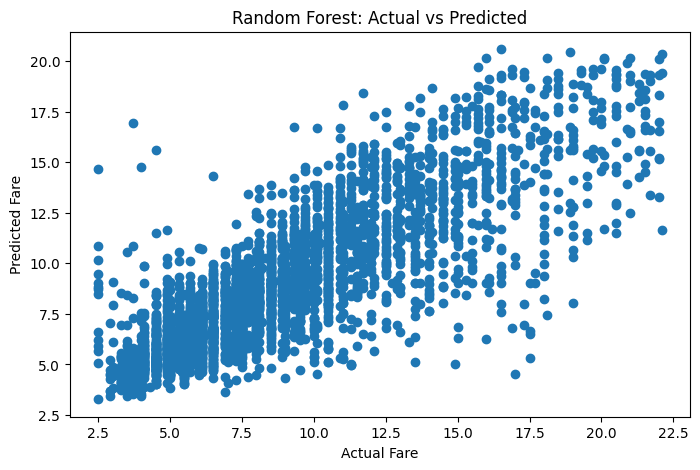

In [18]:
plt.figure(figsize=(8, 5))

plt.scatter(y_test, y_pred_rf)

plt.xlabel("Actual Fare")

plt.ylabel("Predicted Fare")

plt.title("Random Forest: Actual vs Predicted")

plt.show()